# Japan chart examples / 日本データのグラフ例
Run the setup first; put japan.csv beside this notebook. Uses csv and Matplotlib; pandas is not required.
Outputs are generated from the course japan.csv (47 prefectures), not current live statistics.

In [1]:
import csv
import matplotlib.pyplot as plt

# Put japan.csv in the same folder as your notebook.
with open("japan.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

print(len(data), "prefectures")
print(data[0]["Prefecture"], data[0]["総人口"])

47 prefectures
Hokkaido 5140000


## 1. 棒グラフ / Bar chart
人口が多い都道府県は？ / Which prefectures have the largest populations?

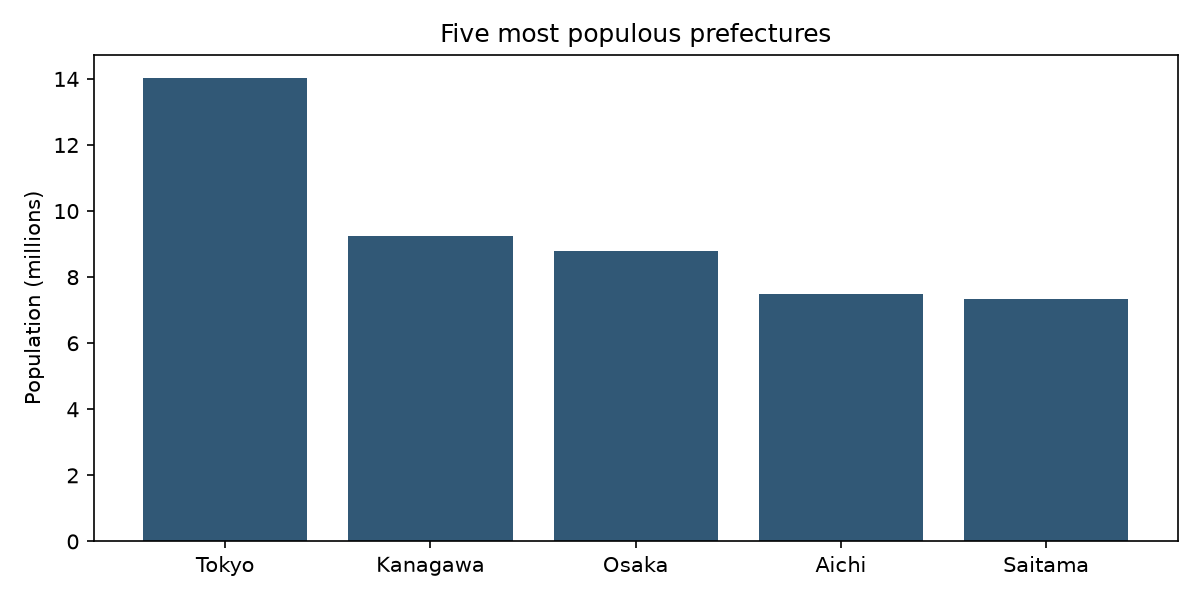

In [2]:
top5 = sorted(data, key=lambda row: int(row["総人口"]), reverse=True)[:5]
names = [row["Prefecture"] for row in top5]
population = [int(row["総人口"]) / 1_000_000 for row in top5]

plt.figure(figsize=(8, 4))
plt.bar(names, population, color="#315876")
plt.ylabel("Population (millions)")
plt.title("Five most populous prefectures")
plt.tight_layout()
plt.show()

## 2. 横棒グラフ / Horizontal bar chart
高齢者の割合が高いのは？ / Where is the share aged 65+ highest?

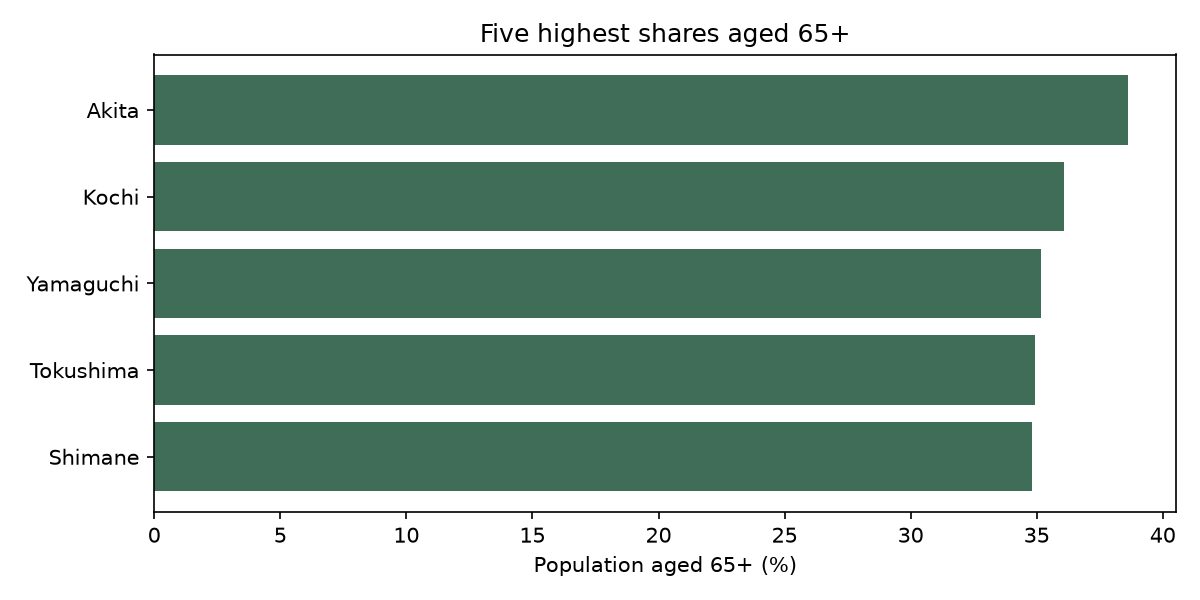

In [3]:
top5 = sorted(data,
              key=lambda row: int(row["65歳以上人口"]) / int(row["総人口"]),
              reverse=True)[:5]
names = [row["Prefecture"] for row in top5]
shares = [int(row["65歳以上人口"]) / int(row["総人口"]) * 100 for row in top5]

plt.figure(figsize=(8, 4))
plt.barh(names, shares, color="#3f6d57")
plt.gca().invert_yaxis()
plt.xlabel("Population aged 65+ (%)")
plt.title("Five highest shares aged 65+")
plt.tight_layout()
plt.show()

## 3. 年齢の積み上げ棒グラフ / Stacked bar
人口の年齢構成を比べよう / Compare age composition.

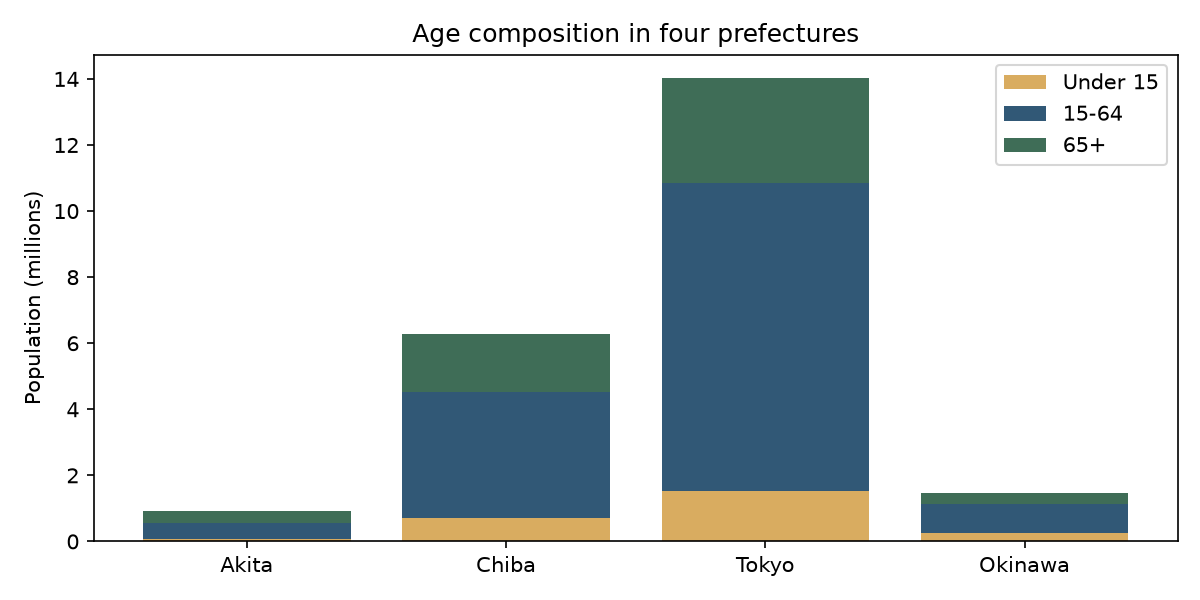

In [4]:
chosen = [row for row in data
          if row["Prefecture"] in ["Tokyo", "Chiba", "Akita", "Okinawa"]]
names = [row["Prefecture"] for row in chosen]
young = [int(row["15歳未満人口"]) / 1_000_000 for row in chosen]
working = [int(row["15～64歳人口"]) / 1_000_000 for row in chosen]
older = [int(row["65歳以上人口"]) / 1_000_000 for row in chosen]
base = [young[i] + working[i] for i in range(len(chosen))]

plt.figure(figsize=(8, 4))
plt.bar(names, young, label="Under 15", color="#d9ac60")
plt.bar(names, working, bottom=young, label="15-64", color="#315876")
plt.bar(names, older, bottom=base, label="65+", color="#3f6d57")
plt.ylabel("Population (millions)")
plt.title("Age composition in four prefectures")
plt.legend()
plt.tight_layout()
plt.show()

## 4. 100%積み上げ棒グラフ / 100% stacked bar
人口の規模をそろえ、年齢構成の割合を比べよう / Compare age shares on the same scale.

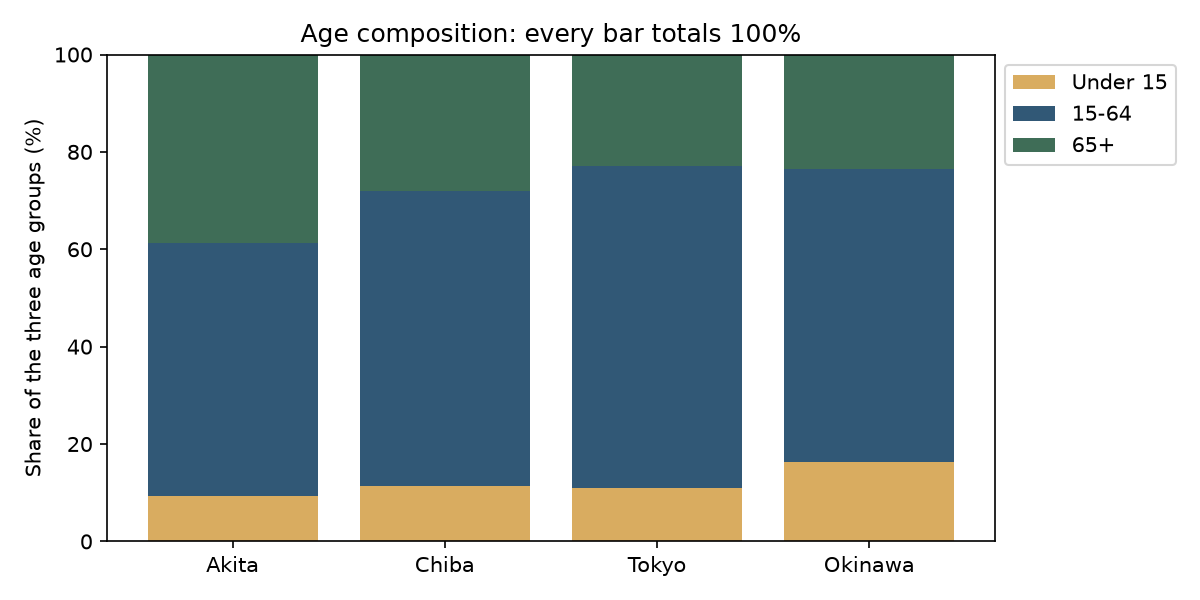

In [5]:
chosen = [row for row in data
          if row["Prefecture"] in ["Tokyo", "Chiba", "Akita", "Okinawa"]]
names = [row["Prefecture"] for row in chosen]
young = [int(row["15歳未満人口"]) for row in chosen]
working = [int(row["15～64歳人口"]) for row in chosen]
older = [int(row["65歳以上人口"]) for row in chosen]

# Divide each age group by the sum of all three age groups.
totals = [young[i] + working[i] + older[i] for i in range(len(chosen))]
young = [young[i] / totals[i] * 100 for i in range(len(chosen))]
working = [working[i] / totals[i] * 100 for i in range(len(chosen))]
older = [older[i] / totals[i] * 100 for i in range(len(chosen))]
base = [young[i] + working[i] for i in range(len(chosen))]

plt.figure(figsize=(8, 4))
plt.bar(names, young, label="Under 15", color="#d9ac60")
plt.bar(names, working, bottom=young, label="15-64", color="#315876")
plt.bar(names, older, bottom=base, label="65+", color="#3f6d57")
plt.ylim(0, 100)
plt.ylabel("Share of the three age groups (%)")
plt.title("Age composition: every bar totals 100%")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 5. ヒストグラム / Histogram
高齢者の割合は、どの範囲に集中する？ / How are the 47 shares distributed?

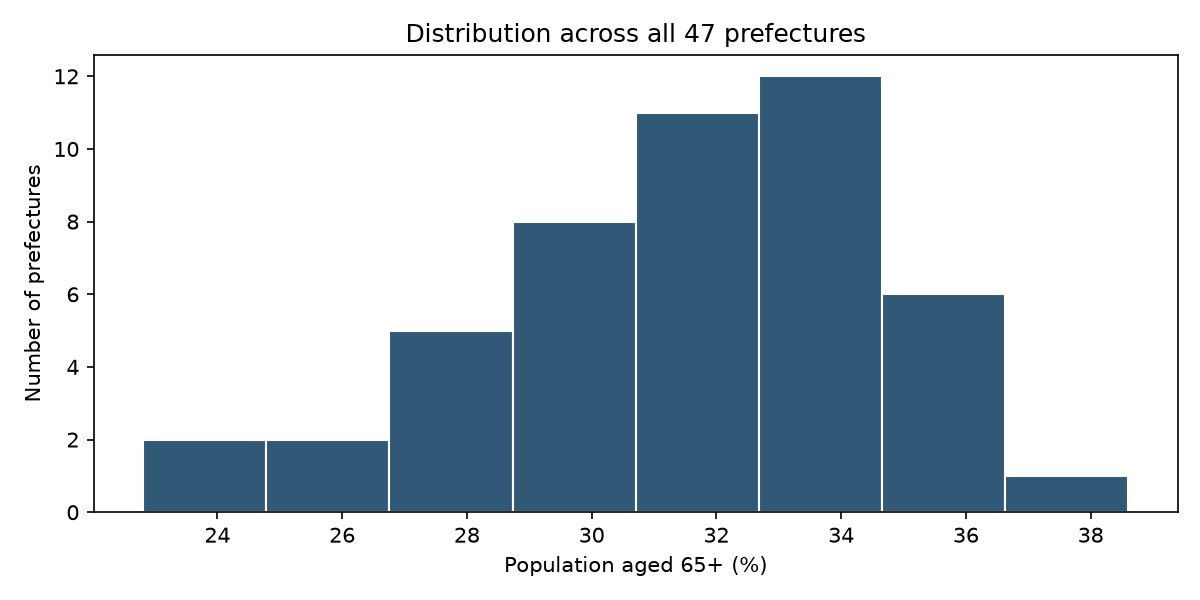

In [6]:
shares = [int(row["65歳以上人口"]) / int(row["総人口"]) * 100
          for row in data]

plt.figure(figsize=(8, 4))
plt.hist(shares, bins=8, color="#315876", edgecolor="white")
plt.xlabel("Population aged 65+ (%)")
plt.ylabel("Number of prefectures")
plt.title("Distribution across all 47 prefectures")
plt.tight_layout()
plt.show()

## 6. 箱ひげ図 / Box plot
中央値とばらつきを一目で見る / Summarize the same 47 shares.

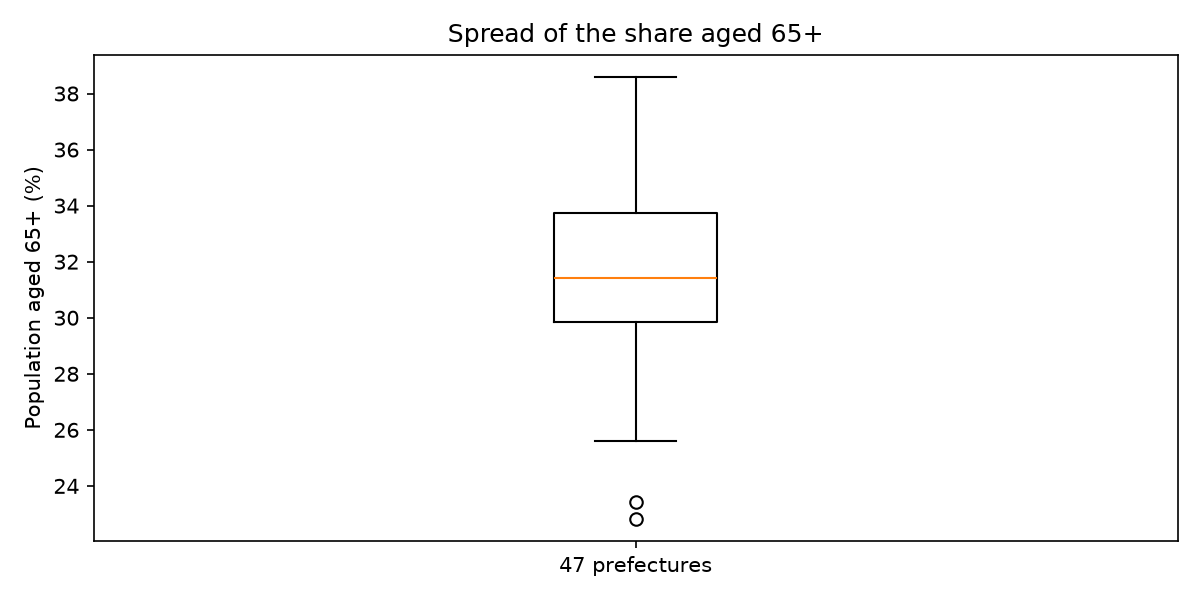

In [7]:
shares = [int(row["65歳以上人口"]) / int(row["総人口"]) * 100
          for row in data]

plt.figure(figsize=(8, 4))
plt.boxplot(shares)
plt.xticks([1], ["47 prefectures"])
plt.ylabel("Population aged 65+ (%)")
plt.title("Spread of the share aged 65+")
plt.tight_layout()
plt.show()

## 7. 散布図 / Scatter plot
2つの数値の関係を探す / Compare two variables.

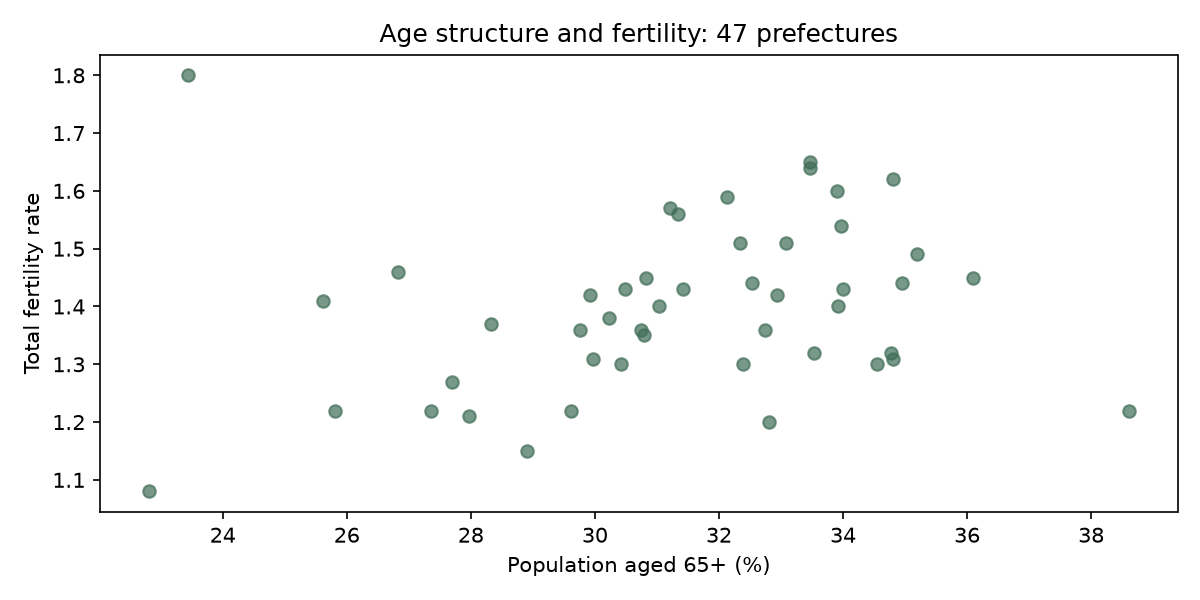

In [8]:
shares = [int(row["65歳以上人口"]) / int(row["総人口"]) * 100
          for row in data]
fertility = [float(row["合計特殊出生率"]) for row in data]

plt.figure(figsize=(8, 4))
plt.scatter(shares, fertility, color="#3f6d57", alpha=0.7)
plt.xlabel("Population aged 65+ (%)")
plt.ylabel("Total fertility rate")
plt.title("Age structure and fertility: 47 prefectures")
plt.tight_layout()
plt.show()

## 8. forで複数のグラフ / One loop, two charts
同じ処理を、違う県に使う / Repeat a chart for each prefecture.

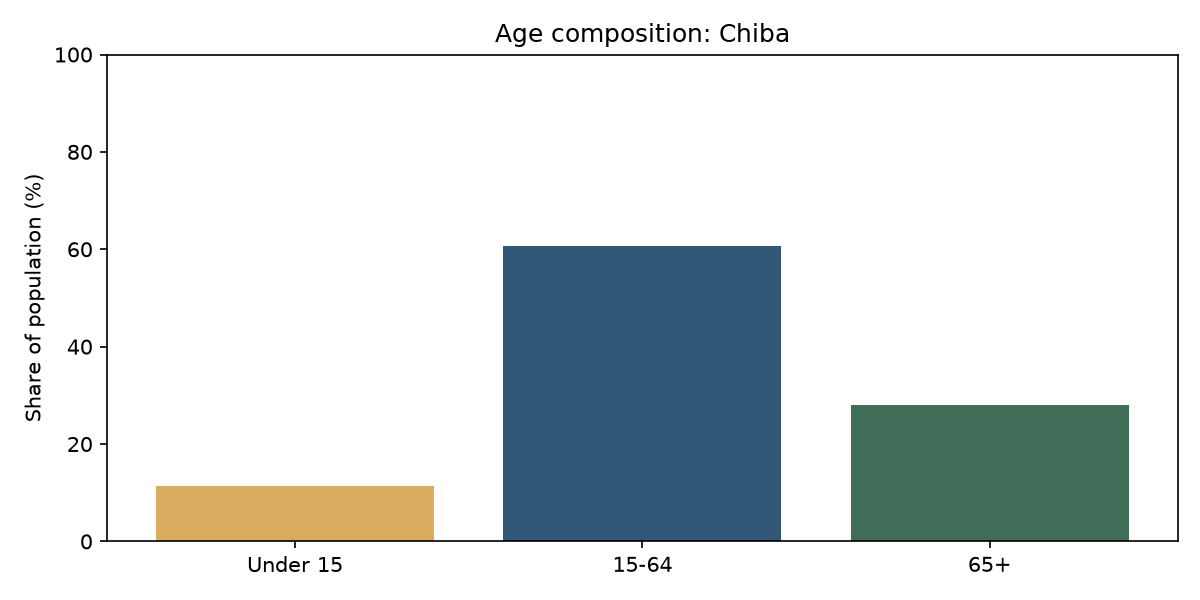

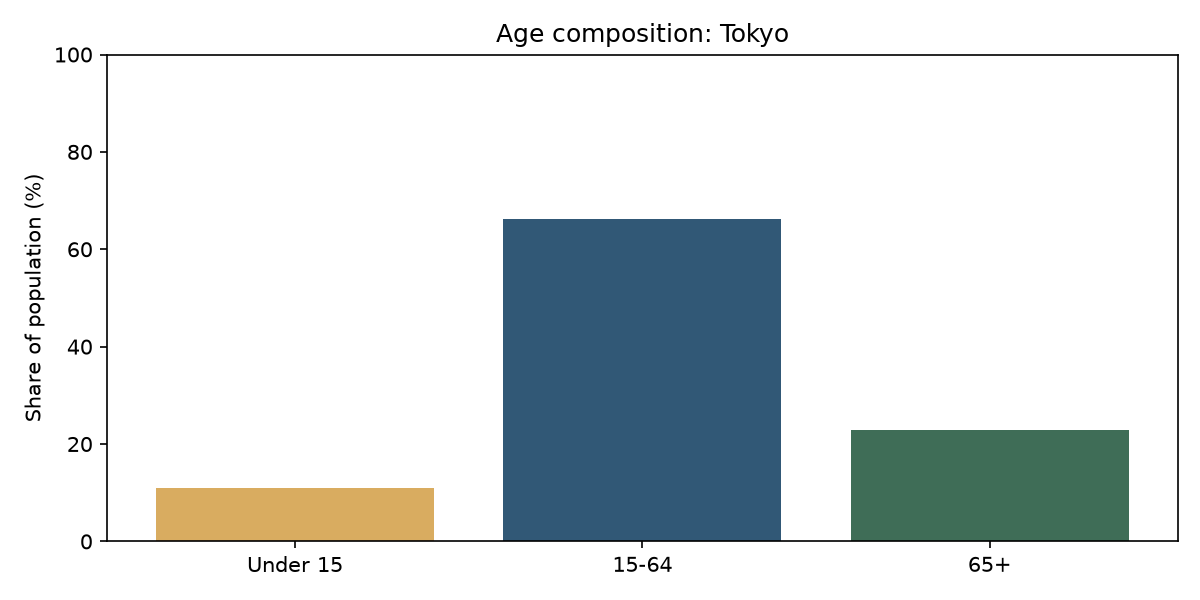

In [9]:
chosen = [row for row in data if row["Prefecture"] in ["Tokyo", "Chiba"]]

for row in chosen:
    total = int(row["総人口"])
    shares = [int(row["15歳未満人口"]) / total * 100,
              int(row["15～64歳人口"]) / total * 100,
              int(row["65歳以上人口"]) / total * 100]

    plt.figure(figsize=(8, 4))
    plt.bar(["Under 15", "15-64", "65+"], shares,
            color=["#d9ac60", "#315876", "#3f6d57"])
    plt.ylim(0, 100)
    plt.ylabel("Share of population (%)")
    plt.title(f"Age composition: {row['Prefecture']}")
    plt.tight_layout()
    plt.show()